# Noisy simulation

Real quantum computers are noisy. In this tutorial you will learn how to describe the noise of a device with a `NoiseModel`, how to compute noisy expectation values with the HSMPO surrogate, how to check them against an exact density-matrix simulation, and how to sweep the noise strength.

## Setup

Besides `mpstab`, we use qibo for the gate types and matplotlib for the plots. `set_style()` applies the plot style shared by all mpstab tutorials.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import (
    HSMPO,
    CoherentError,
    DepolarizingError,
    NoiseModel,
    PauliError,
    ReadoutError,
    pauli_string_to_hamiltonian,
)
from mpstab.models.ansatze import ParametricKickedIsing
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()

## The circuit

We simulate three steps of a kicked Ising chain on 8 qubits. Its Clifford skeleton is maximally entangling, and `delta_h` moves the transverse kicks away from Clifford, adding magic. The Ising couplings are compiled as `CNOT · RZ · CNOT`, so the two-qubit gates are CNOTs. We measure the nearest-neighbour energy $H = \sum_i Z_i Z_{i+1}$.

In [2]:
NQUBITS = 8

ansatz = ParametricKickedIsing(nqubits=NQUBITS, n_steps=3, delta_h=0.2)
circuit = ansatz.circuit


def zz(i, n=NQUBITS):
    return "".join("Z" if q in (i, i + 1) else "I" for q in range(n))


energy = {zz(i): 1.0 for i in range(NQUBITS - 1)}

hsmpo = HSMPO(ansatz, progress=False)
ideal = hsmpo.expectation(energy)
print(f"{len(circuit.queue)} gates, {hsmpo.n_magic_gates} magic gates")
print(f"noiseless <H> = {ideal:+.5f}")

111 gates, 24 magic gates
noiseless <H> = +0.56761


## Building a noise model

A `NoiseModel` is built rule by rule, as in qibo. `noise.add(error, gate, qubits)` puts `error` right after every gate of type `gate` (every gate if omitted), optionally only on some qubits. Four kinds of errors cover most needs:

| error | what it describes |
|---|---|
| `PauliError({"X": p, ...})` | random Pauli flips; a label as wide as the gate (`"ZZ"`) acts jointly on its qubits |
| `DepolarizingError(lam)` | depolarizing channel on the gate's qubits |
| `CoherentError("ZZ", angle)` | a small unwanted rotation $e^{-i\,\text{angle}\,P/2}$, such as a residual coupling |
| `ReadoutError(p)` | bit flips of the measured outcomes |

In [3]:
noise = NoiseModel()
noise.add(PauliError({"X": 3e-4, "Y": 3e-4, "Z": 3e-4}))      # every gate
noise.add(DepolarizingError(2e-3), gates.CNOT)                # two-qubit gate error
noise.add(PauliError({"ZZ": 1e-3}), gates.CNOT)               # correlated dephasing
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)              # residual ZZ coupling
noise.add(CoherentError("X", 0.01), gates.RX, qubits=[0, 1])  # over-rotation on two qubits

print(len(noise.events(circuit)), "errors inserted in the circuit")

291 errors inserted in the circuit


## Noisy expectation values

`hsmpo.noisy_expectation` sits next to `hsmpo.expectation`. It returns a `NoisyExpectation`, with the value in `mean` and its statistical error in `stderr`.

How it works: a Pauli fault pulled through the Clifford part of the circuit leaves the stabilizer tableau unchanged and only flips the sign of some later magic rotations. The noisy value is therefore an average of noiseless HSMPO values over sign patterns. Patterns with zero or one fault are summed exactly, patterns with two or more are sampled (`n_samples` of them), and only these contribute to `stderr`.

In [4]:
start = time.perf_counter()
result = hsmpo.noisy_expectation(energy, noise, n_samples=1000, seed=0)
elapsed = time.perf_counter() - start

print(f"noiseless <H> = {ideal:+.5f}")
print(f"noisy     <H> = {result.mean:+.5f} ± {result.stderr:.1e}   ({elapsed:.1f} s)")

noiseless <H> = +0.56761
noisy     <H> = +0.59257 ± 1.2e-04   (10.0 s)


## Checking against the exact density matrix

`noise.apply(circuit)` returns the same noisy circuit as a qibo density-matrix circuit, so on small systems an exact reference is one line away. Readout errors act on the measured bits, not on the state, so they are not in that circuit: `noise.readout_observable` folds them into the observable instead. The helper below handles both.

In [5]:
def exact_expectation(noise, observable):
    constant, terms = noise.readout_observable(observable, NQUBITS)
    rho = noise.apply(circuit)().state()
    return constant + sum(
        c * pauli_string_to_hamiltonian(p).expectation_from_state(rho) for p, c in terms.items()
    )


exact = exact_expectation(noise, energy)
print(f"exact  <H> = {exact:+.5f}")
print(f"mpstab <H> = {result.mean:+.5f} ± {result.stderr:.1e}")
print(f"difference   {abs(result.mean - exact):.1e}")

exact  <H> = +0.59257
mpstab <H> = +0.59257 ± 1.2e-04
difference   2.3e-06


## Readout noise

`ReadoutError(p)` flips each measured bit with probability `p`. Since an expectation value is estimated from measured bits, every Pauli factor on a noisy qubit is damped by $1 - 2p$. Errors on the same qubit compose, so a worse qubit can get an extra error.

In [6]:
with_readout = NoiseModel(list(noise.rules))
with_readout.add(ReadoutError(0.01))
with_readout.add(ReadoutError(0.03), qubits=[0])

result_ro = hsmpo.noisy_expectation(energy, with_readout, n_samples=1000, seed=0)
print("readout attenuation per qubit:", with_readout.readout_attenuation(NQUBITS).round(3))
print(f"gate noise only  <H> = {result.mean:+.5f}")
print(f"+ readout noise  <H> = {result_ro.mean:+.5f}   (exact {exact_expectation(with_readout, energy):+.5f})")

readout attenuation per qubit: [0.921 0.98  0.98  0.98  0.98  0.98  0.98  0.98 ]
gate noise only  <H> = +0.59257


+ readout noise  <H> = +0.56572   (exact +0.56572)


## Sweeping the noise strength

`noise.scaled(factor)` returns a copy of the model with every probability and angle multiplied by `factor`. Sweeps like this are the starting point of error-mitigation methods such as zero-noise extrapolation. At each strength we compare `mpstab` with the exact density matrix.

In [7]:
factors = np.array([0, 1, 2, 3, 4])
results = [hsmpo.noisy_expectation(energy, noise.scaled(f), n_samples=1000, seed=0) for f in factors]
exacts = [exact_expectation(noise.scaled(f), energy) for f in factors]

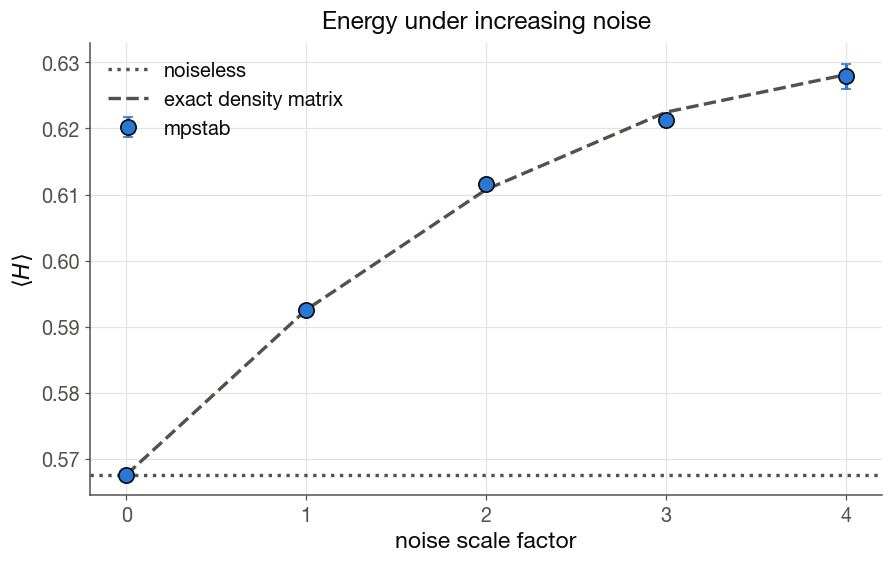

In [8]:
fig, ax = plt.subplots()
ax.axhline(ideal, color=COLORS["gray"], ls=":", label="noiseless")
ax.plot(factors, exacts, "--", color=COLORS["gray"], label="exact density matrix")
ax.errorbar(factors, [r.mean for r in results], yerr=[r.stderr for r in results],
            fmt="o", label="mpstab")
ax.set_xticks(factors)
ax.set_xlabel("noise scale factor")
ax.set_ylabel(r"$\langle H \rangle$")
ax.set_title("Energy under increasing noise")
ax.legend()
plt.show()

The noise model is a mix of stochastic and coherent errors, so the energy does not simply decay towards zero: the residual $ZZ$ coupling shifts the Ising angles and pushes the energy *up*. `mpstab` follows the exact curve at every strength.

## Beyond density matrices

`noisy_expectation` never builds a $4^n$ object: its cost is the number of sign patterns times the cost of one noiseless HSMPO evaluation. The same noise model therefore runs unchanged on long chains, where `max_bond_dimension` sets the accuracy of each evaluation.

We measure a local $Z_iZ_{i+1}$ in the middle of the chain. Only the gates and errors in its light cone can affect it, and `mpstab` drops all the others exactly, so the cost hardly depends on the chain length. A global observable, such as the full energy, has a light cone that grows with the chain, and costs more.

In [9]:
print(" n    noiseless   noisy               time")
for n in (16, 100):
    surrogate = HSMPO(ParametricKickedIsing(nqubits=n, n_steps=3, delta_h=0.2),
                      max_bond_dimension=32, progress=False)
    local = zz(n // 2, n)
    start = time.perf_counter()
    res = surrogate.noisy_expectation(local, noise, n_samples=500, seed=0)
    print(f"{n:3d}   {surrogate.expectation(local):+.4f}     {res.mean:+.4f} ± {res.stderr:.0e}"
          f"   {time.perf_counter() - start:4.1f} s")

 n    noiseless   noisy               time


 16   +0.1123     +0.1009 ± 2e-05    2.7 s


100   +0.1123     +0.1009 ± 2e-05   13.3 s


A 100-qubit density matrix would need $4^{100}$ entries. Because the light cone has a fixed size, both chains give the same value: the bulk value of an infinite chain.

## Summary

```python
noise = NoiseModel()
noise.add(DepolarizingError(1e-3))                 # after every gate
noise.add(PauliError({"ZZ": 5e-4}), gates.CNOT)    # correlated, on CNOTs
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)   # residual coupling
noise.add(ReadoutError(0.01))                      # readout bit flips

noisy = hsmpo.noisy_expectation(obs, noise)        # noisy.mean, noisy.stderr
exact = noise.apply(circuit)                       # qibo density-matrix circuit
stronger = noise.scaled(2.0)                       # noise-strength sweeps
```

The "Device-level noise" tutorial adds relaxation, crosstalk, idle noise and preparation errors. The "Error mitigation" tutorial uses these noise models for Clifford data regression.